In [1]:
from pathlib import Path
# import os, random
import numpy as np
import cv2
# from google.colab import drive
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
# from tensorflow.keras.utils import to_categorical
from google.colab import drive
import tensorflow as tf
from tensorflow.keras import models, layers

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("karapy/neurovision")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/karapy/neurovision


In [3]:
DATA = Path('/kaggle/input/datasets/karapy/neurovision/Data/')

In [4]:
# drive.mount('/content/drive')

In [5]:
# DATA = Path('/content/drive/MyDrive/NeuroVision/Data/raw/')
SIZE = (224, 224)
EXTS = {'.jpeg', '.jpg', '.bmp', '.png'}
RANDOM_SEED = 42

In [6]:
# get classes names

arr_names = []
for folder in DATA.iterdir():
    arr_names.append(folder.name)

arr_names

['pituitary', 'notumor', 'meningioma', 'glioma']

In [7]:
def load_dataset(data_dir=DATA, arr_names=arr_names, size=SIZE):

    imgs, labels = [], []

    for class_name in arr_names:

        image_path = (data_dir/class_name)

        for path in image_path.iterdir():

            try:
                if path.suffix.lower() not in EXTS:
                    continue
                img = cv2.imread(str(path))
                if img is None:
                    raise ValueError("unreadable file")

                img = cv2.resize(img, size)

                imgs.append(img)
                labels.append(class_name)

            except Exception as e:
                print(f"Skipped {path.name}: {e}")

    return np.array(imgs, dtype='uint8'), np.array(labels)

In [8]:
images, labels = load_dataset()
print(images.shape, labels.shape, images.dtype)


(7023, 224, 224, 3) (7023,) uint8


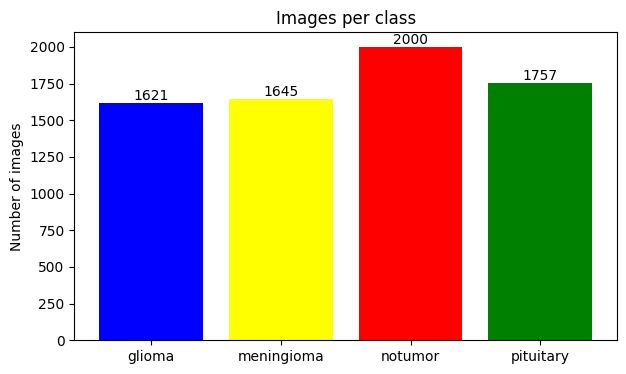

In [9]:
# class distrbution

classes, counts = np.unique(labels, return_counts=True)

plt.figure(figsize=(7, 4))
bars = plt.bar(classes, counts, color=['blue', 'yellow', 'red', 'green'])
plt.bar_label(bars)
plt.title("Images per class")
plt.ylabel("Number of images")
plt.show()

In [10]:
# Check the images and class distribution

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Data type:", images.dtype)
print("Pixel range:", images.min(), images.max())
print("Classes:", arr_names)

Images: (7023, 224, 224, 3)
Labels: (7023,)
Data type: uint8
Pixel range: 0 255
Classes: ['pituitary', 'notumor', 'meningioma', 'glioma']


In [11]:
# split the dataset

le = LabelEncoder()
labels_int = le.fit_transform(labels)

X_train, X_temp, y_train, y_temp = train_test_split( images,
                                                    labels_int,
                                                    test_size=0.2,
                                                    stratify=labels_int,
                                                    random_state=RANDOM_SEED
                                                    )

X_val, X_test, y_val, y_test = train_test_split( X_temp,
                                                y_temp,
                                                test_size=0.5,
                                                stratify=y_temp,
                                                random_state=RANDOM_SEED
                                                )

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Class mapping:", dict(enumerate(le.classes_)))


Train: (5618, 224, 224, 3) (5618,)
Validation: (702, 224, 224, 3) (702,)
Test: (703, 224, 224, 3) (703,)
Class mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}


In [13]:
# Normalize pixel values

X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0


In [14]:
my_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3),activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3),activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Block 4
    layers.Conv2D(256, (3, 3),activation="relu", padding="same"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification head
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

my_model.summary()

I0000 00:00:1792152659.045755     598 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5436 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792152659.047916     598 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13654 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,828 (1.61 MB)

 Trainable params: 421,828 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
my_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history = my_model.fit(X_train,y_train,epochs=15,batch_size=32,validation_split=0.2,verbose=2)

Epoch 1/15


I0000 00:00:1792152674.432841     641 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


141/141 - 25s - 178ms/step - accuracy: 0.3818 - loss: 1.2295 - val_accuracy: 0.4831 - val_loss: 1.0884
Epoch 2/15
141/141 - 9s - 66ms/step - accuracy: 0.5788 - loss: 0.9918 - val_accuracy: 0.5943 - val_loss: 0.8872
Epoch 3/15
141/141 - 9s - 65ms/step - accuracy: 0.6931 - loss: 0.7809 - val_accuracy: 0.7278 - val_loss: 0.6835
Epoch 4/15
141/141 - 9s - 64ms/step - accuracy: 0.7283 - loss: 0.6985 - val_accuracy: 0.7687 - val_loss: 0.5847
Epoch 5/15
141/141 - 9s - 64ms/step - accuracy: 0.7483 - loss: 0.6326 - val_accuracy: 0.7447 - val_loss: 0.6149
Epoch 6/15
141/141 - 9s - 64ms/step - accuracy: 0.7768 - loss: 0.5773 - val_accuracy: 0.7963 - val_loss: 0.5389
Epoch 7/15
141/141 - 9s - 64ms/step - accuracy: 0.7913 - loss: 0.5353 - val_accuracy: 0.7963 - val_loss: 0.5044
Epoch 8/15
141/141 - 9s - 65ms/step - accuracy: 0.8004 - loss: 0.5007 - val_accuracy: 0.8016 - val_loss: 0.4795
Epoch 9/15
141/141 - 9s - 65ms/step - accuracy: 0.8129 - loss: 0.4787 - val_accuracy: 0.8149 - val_loss: 0.4540
E

In [16]:
predictions = my_model.predict(X_test)
print("Predicted class:", np.argmax(predictions[0]))
print("Actual class:", np.argmax(y_test[0]))

22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step
Predicted class: 3
Actual class: 0


In [ ]:
y_val[4]

np.int64(3)